# Tutorial: 1D and 2D Time-Dependent Ginzburg-Landau (TDGL) Simulations

**Authors:** Chandranil Das (261340004) and Devkinandan Sharma (261340005)  
**Affiliation:** Kotak School of Sustainability, M.Tech in AI for Sustainability  
**Course & Date:** IDC606 | 14 November 2026  

---

### Target Audience & Learning Goals
- **Audience**: Students and researchers studying nonconserved phase-ordering kinetics (Model-A), numerical PDEs, and finite-difference gradient flows.
- **Prerequisites**: Basic knowledge of reaction-diffusion equations, central finite differences, and Python (`numpy`, `matplotlib`).
- **Learning Goals**:
  1. Understand the real scalar nonconserved Model-A TDGL equation and its unshifted Ginzburg-Landau free energy functional.
  2. Run fast, interactive 1D and 2D periodic simulations using the scientific solvers.
  3. Clearly distinguish fast interactive demonstration settings from the full-length project runs.
  4. Verify core mathematical and physical invariants: uniform fixed points ($\phi \in \{0, \pm 1\}$), spatial truncation error convergence ($O(\Delta x^2)$ on an analytical kink), and sampled free energy descent.
  5. Load and inspect the archived computed fields for 1D ordering, 2D coarsening and 1D kink-antikink annihilation.
  6. Inspect late-time Fourier power spectra and evaluate finite-window Porod scaling regressions.

## Outline

1. [Mathematical Formulation & Free Energy](#1.-Mathematical-Formulation-&-Free-Energy)
2. [Setup & Scientific Environment](#2.-Setup-&-Scientific-Environment)
3. [Step 1: Uniform Fixed Points & Linear Stability](#3.-Step-1:-Uniform-Fixed-Points-&-Linear-Stability)
4. [Step 2: Fast 1D Simulation Demonstration](#4.-Step-2:-Fast-1D-Simulation-Demonstration)
5. [Step 3: Fast 2D Simulation Demonstration (Domain Coarsening)](#5.-Step-3:-Fast-2D-Simulation-Demonstration-(Domain-Coarsening))
6. [Step 4: Spatial Order Verification (Analytical Kink Residual)](#6.-Step-4:-Spatial-Order-Verification-(Analytical-Kink-Residual))
7. [Step 5: Sampled Free Energy Evolution](#7.-Step-5:-Sampled-Free-Energy-Evolution)
8. [Step 6: Loading & Plotting Archived Full Project Runs](#8.-Step-6:-Loading-&-Plotting-Archived-Authoritative-Research-Runs)
9. [Step 7: Optional Spectral Diagnostics & Porod Scaling](#9.-Step-7:-Optional-Spectral-Diagnostics-&-Porod-Scaling)
10. [Step 8: Command-Line Reproduction Pipeline](#10.-Step-8:-Command-Line-Reproduction-Pipeline)
11. [References](#11.-References)

## 1. Mathematical Formulation & Free Energy

The real scalar nonconserved Model-A Time-Dependent Ginzburg-Landau (TDGL) equation governs the relaxation of an order parameter $\phi(\mathbf{x}, t)$ towards equilibrium wells $\phi = \pm 1$:

$$\partial_t \phi = \phi - \phi^3 + \nabla^2 \phi = -\frac{\delta F}{\delta \phi}$$

### Unshifted Free Energy Functional
The simulation codebase implements the unshifted Ginzburg-Landau free energy functional:

$$F[\phi] = \int d^d x \left[ -\frac{1}{2}\phi^2 + \frac{1}{4}\phi^4 + \frac{1}{2}|\nabla \phi|^2 \right]$$

For a uniform equilibrium state $\phi(\mathbf{x}) \equiv \pm 1$, the gradient term vanishes and the local bulk potential evaluates to:

$$V(\pm 1) = -\frac{1}{2}(1)^2 + \frac{1}{4}(1)^4 = -\frac{1}{4}$$

Therefore, the global minimum free energy of the ordered ground state is:

$$F_{\text{min}} = -\frac{1}{4} \times \text{Volume}$$

- In 1D with system length $L=100$: $F_{\text{min}} = -L/4 = -25.0$.
- In 2D with box size $L=128$: $F_{\text{min}} = -L^2/4 = -4096.0$.

### Discrete Variational Gradient Consistency
On a uniform cartesian grid with periodic boundary conditions, the discrete free energy is evaluated using forward edge differences:

$$F_d[\phi] = \sum_i \Delta x \left[ -\frac{1}{2}\phi_i^2 + \frac{1}{4}\phi_i^4 + \frac{1}{2}\left(\frac{\phi_{i+1} - \phi_i}{\Delta x}\right)^2 \right]$$

Differentiating $F_d$ with respect to $\phi_i$ yields:

$$-\frac{1}{\Delta x} \frac{\partial F_d}{\partial \phi_i} = \phi_i - \phi_i^3 + \frac{\phi_{i+1} - 2\phi_i + \phi_{i-1}}{\Delta x^2}$$

This demonstrates exact discrete gradient consistency: the negative discrete gradient divided by cell volume identically matches the implemented finite-difference right-hand side (RHS).

### Explicit Forward Euler & Stability Criteria
Time advancement proceeds via explicit Forward Euler:

$$\phi^{n+1} = \phi^n + \Delta t \left( \phi^n - (\phi^n)^3 + \nabla_d^2 \phi^n \right)$$

Linearizing about the ordered state $\phi = \pm 1$ yields the ordered-state stability bound (Yadav et al., 2024 PRE [2], Eq. 35):

$$\Delta t \le \Delta t_{\text{max}} = \frac{\Delta x^2}{2d + \Delta x^2} \approx \frac{\Delta x^2}{2d}$$

> **Physical Note on Explicit Euler Energy Behavior**:  
> The linear bound $\Delta t_{\text{max}}$ guarantees decay of small perturbations around the uniform states $\phi = \pm 1$. However, Forward Euler is only conditionally energy-stable; during rapid non-linear interface motion or steep gradient dynamics, explicit Euler can produce transient energy increases at finite $\Delta t$ even below this linear bound.

## 2. Setup & Scientific Environment

We import the scientific simulation modules from `src/` and set up matplotlib for publication-quality figures.

In [1]:
from __future__ import annotations

import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

# Resolve either the repository notebook folder or the submission codes folder.
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.tdgl_core import (
    TDGL1DConfig, TDGL2DConfig,
    laplacian_1d, laplacian_2d,
    free_energy_1d, free_energy_2d,
    tdgl_rhs_1d, tdgl_rhs_2d,
    euler_step_1d, euler_step_2d,
    stability_limit_dt
)
from src.tdgl_1d import simulate_1d
from src.tdgl_2d import simulate_2d
from src.initial_conditions import make_random_ic_1d, make_random_ic_2d, make_kink_1d
from src.validation import validate_fixed_points, validate_kink_convergence, check_free_energy_monotonicity

from src.plot_style import FIELD, ENERGY, MEAN, MOMENT, RMS, MAX_ERROR, RAW, HARDENED, REFERENCE, FIELD_CMAP, time_color

# Plot styling configuration
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
    "lines.linewidth": 1.6
})

SEED = 42
print(f"NumPy version: {np.__version__}")
print(f"Random seed: {SEED}")

NumPy version: 2.5.4
Random seed: 42


## 3. Step 1: Uniform Fixed Points & Linear Stability

The local potential $V(\phi) = -\frac{1}{2}\phi^2 + \frac{1}{4}\phi^4$ yields the reaction term $f(\phi) = -V'(\phi) = \phi - \phi^3$.  
There are three uniform stationary solutions:
- $\phi = 0$: Unstable uniform state ($f'(0) = 1 > 0$). Small uniform perturbations grow approximately as $e^t$; a Fourier perturbation has growth rate $1-|k|^2$.
- $\phi = +1$ and $\phi = -1$: Linearly stable equilibrium wells ($f'(\pm 1) = -2 < 0$).

We evaluate the numerical residual $\text{RHS} = \phi - \phi^3 + \nabla_d^2\phi$ and one Euler step on these uniform states.

In [2]:
# Evaluate fixed points using validated library routine
fp_results = validate_fixed_points()

print("=" * 60)
print("FIXED POINT VERIFICATION RESULTS")
print("=" * 60)
for state, data in fp_results.items():
    print(f"\n[{state}]")
    for k, v in data.items():
        print(f"  {k}: {v}")

# Assert stationary states produce zero residual to machine precision
assert fp_results["fixed_point_plus1"]["is_stationary"], "phi = +1 must be stationary"
assert fp_results["fixed_point_minus1"]["is_stationary"], "phi = -1 must be stationary"
assert fp_results["unstable_point_zero"]["is_unstable"], "phi = 0 must be unstable"
print("\n✓ Invariance assertions passed: phi=±1 are stationary, phi=0 is unstable.")
# Independently check all uniform equilibria in 2D as well.
for a in (-1.0, 0.0, 1.0):
    uniform = np.full((16, 16), a)
    assert np.max(np.abs(tdgl_rhs_2d(uniform, 1.0))) == 0
    assert np.array_equal(euler_step_2d(uniform, 1.0, 0.01), uniform)
assert np.mean(euler_step_2d(np.full((16, 16), 0.01), 1.0, 0.01)) > 0.01
print("2D uniform fixed points and perturbation growth: passed.")


FIXED POINT VERIFICATION RESULTS

[fixed_point_plus1]
  max_residual: 0.0
  max_step_change: 0.0
  is_stationary: True

[fixed_point_minus1]
  max_residual: 0.0
  max_step_change: 0.0
  is_stationary: True

[unstable_point_zero]
  epsilon_initial: 0.01
  mean_after_t0.5: 0.016481681454476264
  expected_linear: 0.01648721270700128
  growth_ratio: 1.6481681454476262
  is_unstable: True

✓ Invariance assertions passed: phi=±1 are stationary, phi=0 is unstable.
2D uniform fixed points and perturbation growth: passed.


## 4. Step 2: Fast 1D Simulation Demonstration

> **Parameter Distinction**:
> - **Interactive Demonstration (Here)**: $L=50.0, N=256, \Delta x \approx 0.1953, \Delta t=0.005, t_{\text{final}}=20.0$ ($4,000$ steps). A short run to illustrate phase separation and domain wall formation.
> - **Full Project Run (Archived)**: $L=100.0, N=1024, \Delta x \approx 0.0977, \Delta t=0.001, t_{\text{final}}=1000.0$ ($10^6$ steps). 
> - **Noise Specification**: Initial fluctuations are drawn uniformly from $[-0.05, 0.05]$, possessing zero expectation ($E[\delta\phi] = 0$). Individual finite-sample realizations have small non-zero sample means that are not artificially forced to zero.

1D Demo: dx=0.1953, dt=0.005, dt_max=0.0187 (safety ratio: 0.267)
Initial 1D field sample mean: -0.000303 (zero expectation)


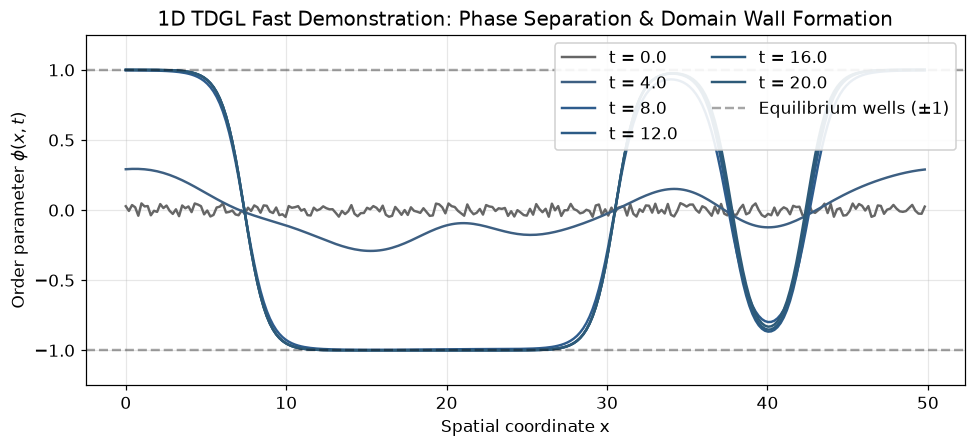

1D Demo completed: 6 snapshots, final mean phi = -0.1073


In [3]:
# 1. Configure fast 1D demonstration
config_1d_demo = TDGL1DConfig(
    L=50.0,
    N=256,
    dt=0.005,
    t_final=20.0
)

# 2. Check linear stability bound (dimension=1)
dt_max_1d = stability_limit_dt(config_1d_demo.dx, 1)
ratio_1d = config_1d_demo.dt / dt_max_1d
print(f"1D Demo: dx={config_1d_demo.dx:.4f}, dt={config_1d_demo.dt}, dt_max={dt_max_1d:.4f} (safety ratio: {ratio_1d:.3f})")
assert config_1d_demo.dt < dt_max_1d, "Timestep exceeds ordered-state linear stability limit"

# 3. Initialize with zero-expectation uniform fluctuations [-0.05, 0.05]
phi_init_1d = make_random_ic_1d(config_1d_demo.N, noise_amplitude=0.05, seed=SEED)
print(f"Initial 1D field sample mean: {np.mean(phi_init_1d):.6f} (zero expectation)")

# 4. Execute simulation (save snapshots every 4.0 time units)
res_1d = simulate_1d(config_1d_demo, phi_init_1d, save_interval=4.0, diag_interval=0.5)

# 5. Visualize field profiles at saved snapshot times
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [time_color(t) for t in res_1d["t_snapshots"]]

for snap, t_val, c in zip(res_1d["snapshots"], res_1d["t_snapshots"], colors):
    ax.plot(res_1d["x"], snap, label=f"t = {t_val:.1f}", color=c)

ax.axhline(1.0, color="k", linestyle="--", alpha=0.35, label="Equilibrium wells (±1)")
ax.axhline(-1.0, color="k", linestyle="--", alpha=0.35)
ax.set_xlabel("Spatial coordinate x")
ax.set_ylabel(r"Order parameter $\phi(x, t)$")
ax.set_title("1D TDGL Fast Demonstration: Phase Separation & Domain Wall Formation")
ax.set_ylim(-1.25, 1.25)
ax.legend(loc="upper right", framealpha=0.9, ncol=2)
plt.tight_layout()
plt.show()

print(f"1D Demo completed: {len(res_1d['t_snapshots'])} snapshots, final mean phi = {res_1d['mean_phi'][-1]:.4f}")

## 5. Step 3: Fast 2D Simulation Demonstration (Domain Coarsening)

> **Parameter Distinction**:
> - **Interactive Demonstration (Here)**: Compact $64 \times 64$ grid, $L=64.0$ ($\Delta x=1.0$), $\Delta t=0.02, t_{\text{final}}=15.0$ ($750$ steps). Demonstrates curvature-driven domain growth in seconds.
> - **Full Project Run (Archived)**: Full $128 \times 128$ grid, $L=128.0$ ($\Delta x=1.0$), $\Delta t=0.01, t_{\text{final}}=100.0$ ($10^4$ steps). 

2D Demo: dx=1.00, dt=0.02, dt_max=0.2000 (safety ratio: 0.100)
Initial 2D field sample mean: -0.000218


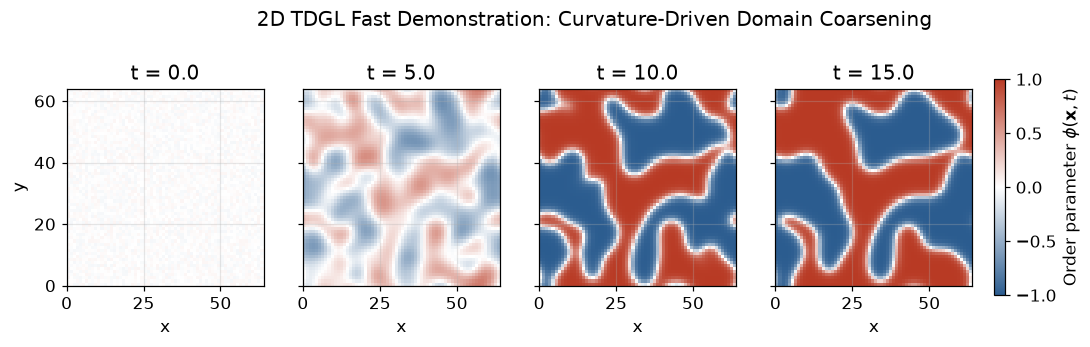

2D Demo completed: final mean order parameter = 0.0232, mean phi^2 = 0.7619


In [4]:
# 1. Configure fast 2D demonstration
config_2d_demo = TDGL2DConfig(
    L=64.0,
    Nx=64,
    Ny=64,
    dt=0.02,
    t_final=15.0
)

# 2. Check linear stability bound (dimension=2)
dt_max_2d = stability_limit_dt(config_2d_demo.dx, 2)
ratio_2d = config_2d_demo.dt / dt_max_2d
print(f"2D Demo: dx={config_2d_demo.dx:.2f}, dt={config_2d_demo.dt}, dt_max={dt_max_2d:.4f} (safety ratio: {ratio_2d:.3f})")
assert config_2d_demo.dt < dt_max_2d, "Timestep exceeds 2D ordered-state linear stability limit"

# 3. Initialize 2D field with zero-expectation noise
phi_init_2d = make_random_ic_2d(config_2d_demo.Nx, config_2d_demo.Ny, noise_amplitude=0.05, seed=SEED)
print(f"Initial 2D field sample mean: {np.mean(phi_init_2d):.6f}")

# 4. Execute 2D simulation
res_2d = simulate_2d(config_2d_demo, phi_init_2d, save_interval=5.0, diag_interval=1.0)

# 5. Visualize 2D coarsening morphology
num_snaps = len(res_2d["t_snapshots"])
fig, axes = plt.subplots(1, num_snaps, figsize=(3.2 * num_snaps, 3.0), sharey=True)

for i, (ax, snap, t_val) in enumerate(zip(axes, res_2d["snapshots"], res_2d["t_snapshots"])):
    im = ax.imshow(
        snap.T,
        origin="lower",
        extent=[0, config_2d_demo.L, 0, config_2d_demo.L],
        cmap=FIELD_CMAP,
        vmin=-1.0,
        vmax=1.0
    )
    ax.set_title(f"t = {t_val:.1f}")
    ax.set_xlabel("x")
    if i == 0:
        ax.set_ylabel("y")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02)
cbar.set_label(r"Order parameter $\phi(\mathbf{x}, t)$")
plt.suptitle("2D TDGL Fast Demonstration: Curvature-Driven Domain Coarsening", y=1.03)
plt.show()

print(f"2D Demo completed: final mean order parameter = {res_2d['mean_phi'][-1]:.4f}, mean phi^2 = {res_2d['mean_phi2'][-1]:.4f}")

## 6. Step 4: Spatial Order Verification (Analytical Kink Residual)

The continuous 1D TDGL equation admits the exact analytical stationary kink solution on an infinite line:

$$\phi_{\text{kink}}(x) = \tanh\left(\frac{x - x_0}{\sqrt{2}}\right)$$

Substituting $\phi_{\text{kink}}$ into the continuous equation gives an exact zero residual:

$$\phi_{\text{kink}} - \phi_{\text{kink}}^3 + \partial_{xx} \phi_{\text{kink}} \equiv 0$$

When evaluated with the discrete central difference Laplacian, the numerical residual is dominated by spatial truncation error:

$$R(x) = \phi - \phi^3 + \nabla_d^2 \phi = \frac{\Delta x^2}{12} \partial_{xxxx}\phi_{\text{kink}} + O(\Delta x^4)$$

Because a single tanh kink is not periodic, evaluating the residual across the box boundaries would introduce boundary wrapping artifacts. To measure pure spatial discretization error, the residual is evaluated strictly on the interior interval $x \in [0.2L, 0.8L]$.

We test grid refinement from $N=128$ to $N=2048$ on $L=60.0$ and confirm second-order spatial convergence ($p \approx 2$).

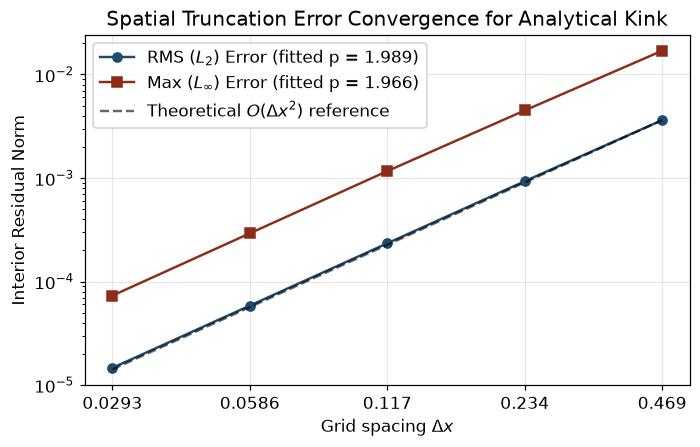

Fitted spatial convergence order: L2 p = 1.9895, Linf p = 1.9664
✓ Second-order spatial convergence confirmed.


In [5]:
# Evaluate interior residual across multiple grid resolutions N
N_resolutions = [128, 256, 512, 1024, 2048]
conv_results = validate_kink_convergence(L=60.0, N_list=N_resolutions)

dxs = conv_results["dx"]
l2_errs = conv_results["l2_errors"]
linf_errs = conv_results["linf_errors"]
p_l2 = conv_results["p_l2"]
p_linf = conv_results["p_linf"]

# Plot convergence on log-log axes
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(dxs, l2_errs, "o-", label=f"RMS ($L_2$) Error (fitted p = {p_l2:.3f})", color=RMS)
ax.loglog(dxs, linf_errs, "s-", label=rf"Max ($L_\infty$) Error (fitted p = {p_linf:.3f})", color=MAX_ERROR)

# Theoretical O(dx^2) reference line
dx_ref = np.linspace(dxs[-1], dxs[0], 50)
ref_line = l2_errs[0] * (dx_ref / dxs[0]) ** 2
ax.loglog(dx_ref, ref_line, "k--", alpha=0.6, label=r"Theoretical $O(\Delta x^2)$ reference")

ax.set_xlabel(r"Grid spacing $\Delta x$")
ax.set_ylabel("Interior Residual Norm")
ax.set_title("Spatial Truncation Error Convergence for Analytical Kink")
ax.legend(framealpha=0.9)
ax.set_xticks(dxs, labels=[f"{h:.3g}" for h in dxs])
ax.set_xticks([], minor=True)
plt.tight_layout()
plt.show()

print(f"Fitted spatial convergence order: L2 p = {p_l2:.4f}, Linf p = {p_linf:.4f}")
assert p_l2 > 1.95, f"Spatial convergence order {p_l2} must be >= 1.95"
print("✓ Second-order spatial convergence confirmed.")

## 7. Step 5: Sampled Free Energy Evolution

During a relaxational gradient flow, the continuous free energy functional satisfies $dF/dt \le 0$.  

In numerical simulations, free energy is recorded at discrete diagnostic intervals (`diag_interval`).  
We inspect the recorded energy series for the fast 1D and 2D demonstrations and check for any non-monotonic increases:

> **Important Distinction on Sampled vs. Stepwise Energy Monitoring**:  
> Plotted diagnostics reflect **sampled times**. Step-by-step energy monitoring across all $1.81 \times 10^6$ integration steps is conducted by the independent verification script `audit/replay_runs.py`, which verified that no step-by-step increase exceeds $10^{-9}$ (floating-point tolerance near equilibrium).

SAMPLED FREE ENERGY EVOLUTION
1D Demo: Initial F = 1.0056, Final F = -8.7494, Drop = 9.7550
         Max Sampled Increase = -2.49e-04, Violations > 1e-9: 0
2D Demo: Initial F = 5.0913, Final F = -703.3622, Drop = 708.4535
         Max Sampled Increase = -1.04e+00, Violations > 1e-9: 0


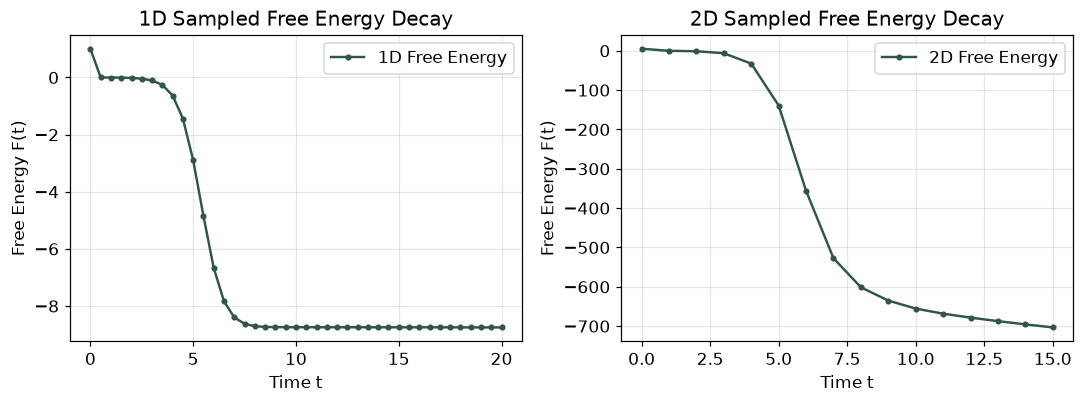

Both sampled energy checks pass at tolerance 1e-9.


In [6]:
# Analyze energy monotonicity on sampled diagnostic times
fe_1d = np.array(res_1d["free_energy"])
mono_1d = check_free_energy_monotonicity(fe_1d, tolerance=1e-9)

fe_2d = np.array(res_2d["free_energy"])
mono_2d = check_free_energy_monotonicity(fe_2d, tolerance=1e-9)

print("=" * 60)
print("SAMPLED FREE ENERGY EVOLUTION")
print("=" * 60)
print(f"1D Demo: Initial F = {fe_1d[0]:.4f}, Final F = {fe_1d[-1]:.4f}, Drop = {mono_1d['total_drop']:.4f}")
print(f"         Max Sampled Increase = {mono_1d['max_increase']:.2e}, Violations > 1e-9: {mono_1d['num_violations']}")
print(f"2D Demo: Initial F = {fe_2d[0]:.4f}, Final F = {fe_2d[-1]:.4f}, Drop = {mono_2d['total_drop']:.4f}")
print(f"         Max Sampled Increase = {mono_2d['max_increase']:.2e}, Violations > 1e-9: {mono_2d['num_violations']}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(res_1d["diag_times"], fe_1d, ".-", color=ENERGY, label="1D Free Energy")
ax1.set_xlabel("Time t")
ax1.set_ylabel("Free Energy F(t)")
ax1.set_title("1D Sampled Free Energy Decay")
ax1.legend()

ax2.plot(res_2d["diag_times"], fe_2d, ".-", color=ENERGY, label="2D Free Energy")
ax2.set_xlabel("Time t")
ax2.set_ylabel("Free Energy F(t)")
ax2.set_title("2D Sampled Free Energy Decay")
ax2.legend()

plt.tight_layout()
plt.show()
assert mono_1d["monotonic"] and mono_2d["monotonic"], "Sampled energy increased above tolerance"
print("Both sampled energy checks pass at tolerance 1e-9.")


## 8. Step 6: Loading & Plotting Archived Full Project Runs

The submission package includes full simulation results for three experiments:
1. **1D ordering**: $L=100, N=1024, \Delta t=0.001, t=0 \to 1000$ ($10^6$ integration steps, 504 snapshots).
2. **2D ordering**: $L=128, 128 \times 128, \Delta t=0.01, t=0 \to 100$ ($10^4$ integration steps, 101 snapshots).
3. **Paired walls**: $L=100, N=1024, R_0=7.0, \Delta t=0.001, t=0 \to 800$ ($8 \times 10^5$ integration steps).


Below, we load the archives and plot:
- The **archived final 1D profile** at $t=1000$ (showing 6 domain walls persisting).
- The **archived final 2D coarsened morphology** at $t=100$.
- The **1D kink-antikink annihilation trajectory** ($R_0=7.0 \to \phi \approx -1$).

### Full simulation results

The full runs follow 1D ordering to $t=1000$, 2D ordering to $t=100$, and paired-wall annihilation to $t=800$. The short demonstrations above use their own stated grids and observation times.

ARCHIVED RESEARCH RUN SUMMARY
1D Random: 504 snapshots, t in [0.0, 1000.0], N=1024


2D Random: 101 snapshots, t in [0.0, 100.0], 128x128
1D Pair:   9 snapshots, t in [0.0, 800.0], R0=7.0


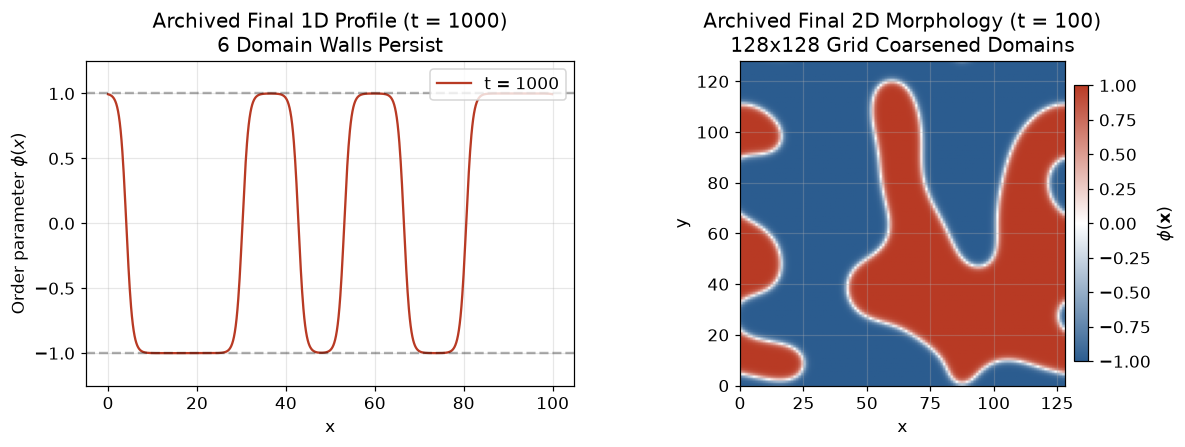

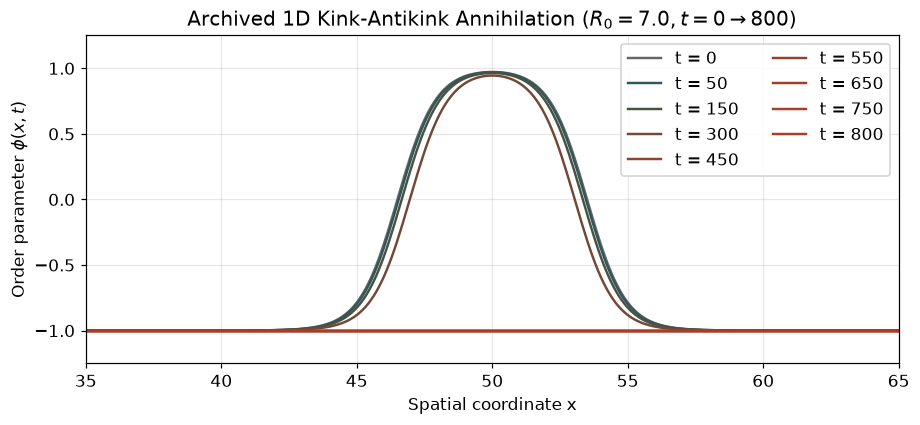

Observation: The kink-antikink pair attracts, collides, and decays into the uniform phi ≈ -1 ground state.


In [7]:
# 1. Load archived arrays
path_1d = "results/raw/tdgl_1d_random.npz"
path_2d = "results/raw/tdgl_2d_random.npz"
path_pair = "results/raw/tdgl_1d_kink_antikink.npz"

data_1d = np.load(path_1d)
data_2d = np.load(path_2d)
data_pair = np.load(path_pair)

print("=" * 65)
print("ARCHIVED RESEARCH RUN SUMMARY")
print("=" * 65)
print(f"1D Random: {data_1d['snapshots'].shape[0]} snapshots, t in [{data_1d['t_snapshots'][0]}, {data_1d['t_snapshots'][-1]}], N={data_1d['N']}")
print(f"2D Random: {data_2d['snapshots'].shape[0]} snapshots, t in [{data_2d['t_snapshots'][0]}, {data_2d['t_snapshots'][-1]}], {data_2d['Nx']}x{data_2d['Ny']}")
print(f"1D Pair:   {data_pair['snapshots'].shape[0]} snapshots, t in [{data_pair['t_snapshots'][0]}, {data_pair['t_snapshots'][-1]}], R0={data_pair['R0']}")

# 2. Plot actual archived final 1D and 2D states
fig, (ax_1d_final, ax_2d_final) = plt.subplots(1, 2, figsize=(11, 4.2))

# 1D Final Profile at t=1000
phi_final_1d = data_1d["snapshots"][-1]
x_1d = data_1d["x"]
t_final_1d = data_1d["t_snapshots"][-1]

ax_1d_final.plot(x_1d, phi_final_1d, "-", color=FIELD, linewidth=1.5, label=f"t = {t_final_1d:.0f}")
ax_1d_final.axhline(1.0, color="k", linestyle="--", alpha=0.3)
ax_1d_final.axhline(-1.0, color="k", linestyle="--", alpha=0.3)
ax_1d_final.set_xlabel("x")
ax_1d_final.set_ylabel(r"Order parameter $\phi(x)$")
ax_1d_final.set_title(f"Archived Final 1D Profile (t = {t_final_1d:.0f})\n6 Domain Walls Persist")
ax_1d_final.set_ylim(-1.25, 1.25)
ax_1d_final.legend(loc="upper right")

# 2D Final Heatmap at t=100
phi_final_2d = data_2d["snapshots"][-1]
t_final_2d = data_2d["t_snapshots"][-1]
L_2d = float(data_2d["L"])

im_2d = ax_2d_final.imshow(
    phi_final_2d.T,
    origin="lower",
    extent=[0, L_2d, 0, L_2d],
    cmap=FIELD_CMAP,
    vmin=-1.0,
    vmax=1.0
)
ax_2d_final.set_xlabel("x")
ax_2d_final.set_ylabel("y")
ax_2d_final.set_title(f"Archived Final 2D Morphology (t = {t_final_2d:.0f})\n128x128 Grid Coarsened Domains")
fig.colorbar(im_2d, ax=ax_2d_final, shrink=0.85, pad=0.02, label=r"$\phi(\mathbf{x})$")

plt.tight_layout()
plt.show()

# 3. Plot Kink-Antikink Annihilation Trajectory
fig, ax_pair = plt.subplots(figsize=(8.5, 4.0))
pair_snaps = data_pair["snapshots"]
pair_times = data_pair["t_snapshots"]
pair_x = data_pair["x"]

pair_colors = [time_color(t) for t in pair_times]
for snap, t_val, c in zip(pair_snaps, pair_times, pair_colors):
    ax_pair.plot(pair_x, snap, label=f"t = {t_val:.0f}", color=c)

ax_pair.set_xlabel("Spatial coordinate x")
ax_pair.set_ylabel(r"Order parameter $\phi(x, t)$")
ax_pair.set_xlim(35, 65)
ax_pair.set_title(r"Archived 1D Kink-Antikink Annihilation ($R_0=7.0, t=0 \to 800$)")
ax_pair.set_ylim(-1.25, 1.25)
ax_pair.legend(loc="upper right", ncol=2, framealpha=0.9)
plt.tight_layout()
plt.show()

print("Observation: The kink-antikink pair attracts, collides, and decays into the uniform phi ≈ -1 ground state.")

### Final-state diagnostics

Calculate the absolute order parameter, quadratic moment and free-energy density from each final field.

In [8]:
from IPython.display import display, Markdown
rows = ["| Run | Mean absolute field | Half squared moment | Free energy | Energy density |", "|---|---:|---:|---:|---:|"]
for label, data in [("1D ordering", data_1d), ("2D ordering", data_2d), ("Paired walls", data_pair)]:
    field = data["snapshots"][-1]
    volume = float(data["L"]) ** field.ndim
    rows.append(f"| {label} | {np.mean(np.abs(field)):.9f} | {np.mean(field**2)/2:.9f} | {data['free_energy'][-1]:.9f} | {data['free_energy'][-1]/volume:.9f} |")
display(Markdown("\n".join(rows)))

| Run | Mean absolute field | Half squared moment | Free energy | Energy density |
|---|---:|---:|---:|---:|
| 1D ordering | 0.882403888 | 0.415169353 | -19.344051079 | -0.193440511 |
| 2D ordering | 0.935438849 | 0.453031248 | -3579.607240902 | -0.218481887 |
| Paired walls | 1.000000000 | 0.500000000 | -25.000000000 | -0.250000000 |

## 9. Step 7: Optional Spectral Diagnostics & Porod Scaling

The Fourier power spectrum of a coarsening field provides descriptive evidence of domain morphology:

$$E(k) = \frac{1}{2} \langle |\hat{\phi}(\mathbf{k})|^2 \rangle$$

Following Yadav et al. (2024 PRE [2], Sec. V B), sharp domain walls introduce Porod tail decay $E(k) \propto k^{-(d+1)}$:
- In 1D ($d=1$): $k^{-2}$
- In 2D ($d=2$): $k^{-3}$ for angle-averaged modal energy

### Hardening Diagnostic
In numerical fields, finite interface widths (order $\xi = \sqrt{2}$) broaden interfaces. Applying the sign-function hardening $\phi_{\text{hard}} = \text{sign}(\phi)$ sharpens the boundaries and clarifies the power-law tail.

### Methodological Limits
We analyze the final-time raw and hardened fields over the fitting windows below.  
> **Scientific Caveat**:  
> These fits represent **descriptive single-realization regressions** over fixed finite wavenumber windows ($k \in [0.1, 1.8]$ in 1D; $k \in [0.15, 1.5]$ in 2D modal). Standard errors are regression-only; they do not include seed, window, or discretization uncertainty. The 1D fit exhibits visible scatter ($R^2 \approx 0.67$). We do **not** claim universal scaling verification from single runs.

SPECTRAL FIT SUMMARY
[1D_hardened]
  Exponent:   -2.0638 ± 0.2907
  R^2:        0.6685
  Fit window: [0.1, 1.8] (27 points)
[2D_hardened_modal]
  Exponent:   -3.0220 ± 0.0657
  R^2:        0.9916
  Fit window: [0.15, 1.5] (20 points)

Fit interpretation: Descriptive single-realization fits. stderr is regression-only; it excludes seed, window and discretization uncertainty.


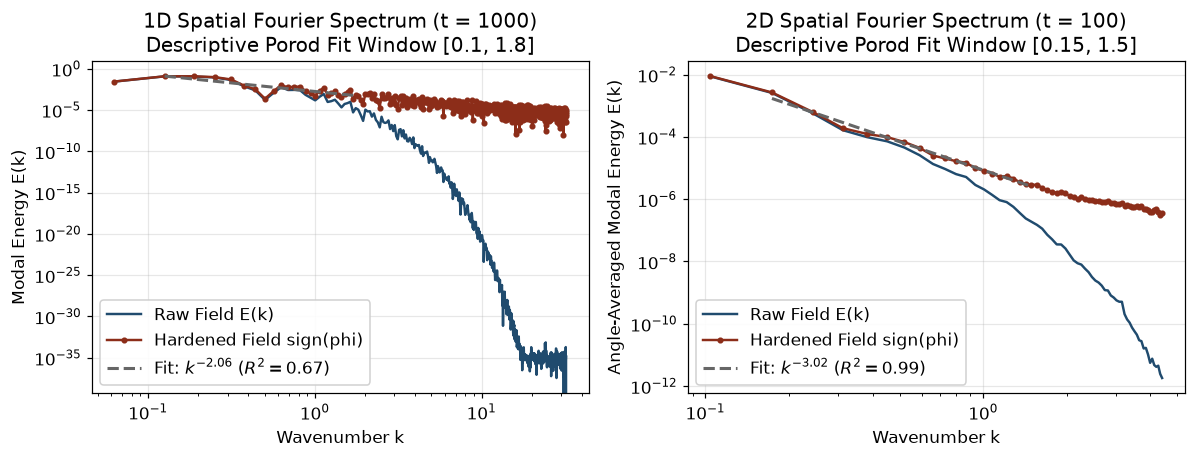

In [9]:
# Load pre-computed spectra and audited fits
spectra_data = np.load("results/raw/spectra_final.npz")
with open("results/validation/spectral_fits.json", "r") as f:
    fits_data = json.load(f)

print("=" * 60)
print("SPECTRAL FIT SUMMARY")
print("=" * 60)
for key, info in fits_data.items():
    if key == "interpretation":
        continue
    print(f"[{key}]")
    print(f"  Exponent:   {info['exponent']:.4f} ± {info['stderr']:.4f}")
    print(f"  R^2:        {info['r_squared']:.4f}")
    print(f"  Fit window: [{info['k_min']}, {info['k_max']}] ({info['num_points']} points)")

print(f"\nFit interpretation: {fits_data['interpretation']}")

# Plot 1D and 2D modal spectra with audited fit lines
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))

# 1D Spectrum (Raw vs Hardened)
k_1d = spectra_data["k_1d"]
raw_1d = spectra_data["raw_1d"]
hard_1d = spectra_data["hardened_1d"]
fit_1d = fits_data["1D_hardened"]

ax1.loglog(k_1d[1:], raw_1d[1:], "-", color=RAW, label="Raw Field E(k)")
ax1.loglog(k_1d[1:], hard_1d[1:], ".-", color=HARDENED, label="Hardened Field sign(phi)")

# 1D Fit line
k_mask_1d = (k_1d >= fit_1d["k_min"]) & (k_1d <= fit_1d["k_max"])
k_fit_1d = k_1d[k_mask_1d]
E_fit_1d = fit_1d["amplitude"] * (k_fit_1d ** fit_1d["exponent"])
ax1.loglog(k_fit_1d, E_fit_1d, "--", color=REFERENCE, linewidth=2.0, label=f"Fit: $k^{{{fit_1d['exponent']:.2f}}}$ ($R^2={fit_1d['r_squared']:.2f}$)")

ax1.set_xlabel("Wavenumber k")
ax1.set_ylabel("Modal Energy E(k)")
ax1.set_title("1D Spatial Fourier Spectrum (t = 1000)\nDescriptive Porod Fit Window [0.1, 1.8]")
ax1.legend(loc="lower left", framealpha=0.9)

# 2D Modal Spectrum
k_2d = spectra_data["k_2d"]
raw_2d = spectra_data["raw_2d_modal"]
hard_2d = spectra_data["hardened_2d_modal"]
fit_2d = fits_data["2D_hardened_modal"]

ax2.loglog(k_2d[1:], raw_2d[1:], "-", color=RAW, label="Raw Field E(k)")
ax2.loglog(k_2d[1:], hard_2d[1:], ".-", color=HARDENED, label="Hardened Field sign(phi)")

# 2D Fit line
k_mask_2d = (k_2d >= fit_2d["k_min"]) & (k_2d <= fit_2d["k_max"])
k_fit_2d = k_2d[k_mask_2d]
E_fit_2d = fit_2d["amplitude"] * (k_fit_2d ** fit_2d["exponent"])
ax2.loglog(k_fit_2d, E_fit_2d, "--", color=REFERENCE, linewidth=2.0, label=f"Fit: $k^{{{fit_2d['exponent']:.2f}}}$ ($R^2={fit_2d['r_squared']:.2f}$)")

ax2.set_xlabel("Wavenumber k")
ax2.set_ylabel("Angle-Averaged Modal Energy E(k)")
ax2.set_title("2D Spatial Fourier Spectrum (t = 100)\nDescriptive Porod Fit Window [0.15, 1.5]")
ax2.legend(loc="lower left", framealpha=0.9)

plt.tight_layout()
plt.show()

## 10. Step 8: Command-Line Reproduction Pipeline

All scientific experiments and independent verification audits can be executed from the terminal in the directory containing `src/` (repository root or submission `codes/`):

```bash
# 1. Run the Python scientific validation test suite (13 tests)
python -m pytest tests/test_tdgl.py -v

# 2. Execute full experimental pipeline (1D/2D random quenches, pair annihilation, convergence)
python experiments/run_all.py

# 3. Run individual experiment scripts
python experiments/run_1d_random.py
python experiments/run_2d_random.py
python experiments/run_1d_kink_antikink.py
python experiments/run_1d_kink.py
python experiments/run_validation.py

# 4. Run independent verification scripts
python audit/check_implementation.py audit/implementation_checks.json
python audit/replay_runs.py
python audit/temporal_convergence.py
python audit/save_spectra.py
```

## 11. References

1. **M. K. Verma, R. Agrawal, P. K. Yadav, and S. Puri**, *Nonlinear energy dissipation and transfers in coarsening systems*, Physical Review E **107**, 034207 (2023). [DOI: 10.1103/PhysRevE.107.034207](https://doi.org/10.1103/PhysRevE.107.034207).
2. **P. K. Yadav, M. K. Verma, and S. Puri**, *Spectral energy transfers in domain growth problems*, Physical Review E **110**, 044130 (2024). [DOI: 10.1103/PhysRevE.110.044130](https://doi.org/10.1103/PhysRevE.110.044130).